# Mini-Project 4: Rainfall Pattern & Crop Suitability Analyser

**Question.** An agricultural extension officer wants to compare rainfall regimes in Kampala, Gulu and Mbarara and tell farmers which
crops suit which months. We build `Region` and `CropRule` classes, correct last year's flawed cosine-similarity method, compare regions with three
similarity measures, detect rainy seasons automatically, and write a short farmer advisory. Logic lives in `src/rainfall.py`.

*Monthly rainfall in mm is illustrative.*

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))          # so that `from src.xxx import ...` works

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42                              # fixed seed -> Restart & Run All is reproducible
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

import math
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy.spatial.distance import cosine as scipy_cosine_distance
from src.rainfall import (MONTHS, Region, CropRule, CROP_RULES, load_regions, suitability_table, suitability_codes,
                          planting_windows, cosine_similarity, verify_cosine, pearson, euclidean, similarity_matrices,
                          detect_peaks, classify_modality, modality_sensitivity)

## Task 1 - The `Region` class

In [2]:
regions = load_regions()
by_name = {r.name: r for r in regions}
print(regions)
display(pd.DataFrame([r.summary() for r in regions]).set_index("region").round(3))

[Region('Kampala', annual=1600 mm), Region('Gulu', annual=1388 mm), Region('Mbarara', annual=1040 mm)]


,annual_mm,mean_mm,wettest,driest,cv
region,,,,,
Kampala,"1,600.000",133.333,May,Sep,0.388
Gulu,"1,388.000",115.667,Aug,Jan,0.642
Mbarara,"1,040.000",86.667,Apr,Jul,0.444


Kampala is the wettest overall (1,600 mm) but Gulu is the most *seasonal*: its CV of 0.64 reflects an almost dry December-February against 150-215 mm
months from April to October. A high CV means the crop calendar matters far more.

## Task 2 - `CropRule` and month-by-month classification

In [3]:
rules = {c.crop: c for c in CROP_RULES}
display(pd.DataFrame([{"crop": c.crop, "suitable monthly rain (mm)": f"{c.min_mm:g} - {c.max_mm:g}", "basis / source": c.source}
                      for c in CROP_RULES]).set_index("crop"))

table = suitability_table(regions, CROP_RULES)
for crop in rules:
    df = pd.DataFrame({r.name: table[(r.name, crop)] for r in regions}, index=MONTHS)
    print(f"\n--- {crop} ---")
    display(df)

,suitable monthly rain (mm),basis / source
crop,,
maize,90 - 200,FAO Irrigation & Drainage Paper 33 (Doorenbos ...
beans,80 - 140,FAO Paper 33: 300-500 mm over a ~3-month cycle...
coffee,100 - 170,"Arabica 1,200-1,500 mm/yr and robusta 1,500-2,..."



--- maize ---


,Kampala,Gulu,Mbarara
Jan,Good for maize,Drought risk,Drought risk
Feb,Good for maize,Drought risk,Drought risk
Mar,Good for maize,Drought risk,Good for maize
Apr,Good for maize,Good for maize,Good for maize
May,Waterlogging risk,Good for maize,Good for maize
Jun,Good for maize,Good for maize,Drought risk
Jul,Good for maize,Good for maize,Drought risk
Aug,Drought risk,Waterlogging risk,Drought risk
Sep,Drought risk,Good for maize,Good for maize
Oct,Good for maize,Good for maize,Good for maize



--- beans ---


,Kampala,Gulu,Mbarara
Jan,Good for beans,Drought risk,Drought risk
Feb,Good for beans,Drought risk,Good for beans
Mar,Waterlogging risk,Drought risk,Good for beans
Apr,Waterlogging risk,Waterlogging risk,Good for beans
May,Waterlogging risk,Waterlogging risk,Good for beans
Jun,Waterlogging risk,Waterlogging risk,Drought risk
Jul,Good for beans,Waterlogging risk,Drought risk
Aug,Drought risk,Waterlogging risk,Drought risk
Sep,Drought risk,Waterlogging risk,Good for beans
Oct,Good for beans,Waterlogging risk,Good for beans



--- coffee ---


,Kampala,Gulu,Mbarara
Jan,Good for coffee,Drought risk,Drought risk
Feb,Good for coffee,Drought risk,Drought risk
Mar,Waterlogging risk,Drought risk,Good for coffee
Apr,Waterlogging risk,Good for coffee,Good for coffee
May,Waterlogging risk,Waterlogging risk,Drought risk
Jun,Waterlogging risk,Good for coffee,Drought risk
Jul,Drought risk,Good for coffee,Drought risk
Aug,Drought risk,Waterlogging risk,Drought risk
Sep,Drought risk,Waterlogging risk,Good for coffee
Oct,Good for coffee,Good for coffee,Good for coffee


**About the thresholds.** They are *monthly equivalents of published seasonal or annual water needs*, not exact agronomic laws. Maize: FAO Irrigation and Drainage Paper 33
(Doorenbos and Kassam) gives roughly 500-800 mm per cycle of about four months, i.e. 125-200 mm/month; we relax the lower bound to 90 mm because soil moisture buffers short dry spells.
Beans: about 300-500 mm over a three-month cycle, i.e. 100-170 mm/month, with the upper bound lowered to 140 mm because beans suffer from waterlogging and disease. Coffee: arabica 1,200-1,500 mm and robusta
1,500-2,000 mm a year (Coste 1992; Antonio 2008, quoted in a coffee agro-climatic zoning study), i.e. about 100-170 mm/month. Crop-water principles are in FAO-56 and the FAO "Crop water needs" manual. Before
use in the field, these bounds should be checked against NARO or MAAIF guidance for the specific variety and soil.

## Task 3 - Fixing last year's cosine-similarity mistake

In [4]:
a, b = by_name["Kampala"].rainfall, by_name["Mbarara"].rainfall

# WRONG (last year): math.cos() takes an ANGLE in radians and returns one number for one input.
print("math.cos(120) =", round(math.cos(120), 4), " <- the cosine of '120 radians'; says nothing about similarity of two vectors")

# RIGHT: cosine similarity = dot(a, b) / (|a| |b|)
mine = cosine_similarity(a, b)
scipy_val = 1 - scipy_cosine_distance(a, b)
print(f"own implementation      : {mine:.6f}")
print(f"1 - scipy cosine distance: {scipy_val:.6f}   agree = {np.isclose(mine, scipy_val)}")
print("dot product =", a @ b, "| |a| =", round(np.linalg.norm(a), 3), "| |b| =", round(np.linalg.norm(b), 3))

# Verify on every pair
for i in range(3):
    for j in range(i + 1, 3):
        m, s, ok = verify_cosine(regions[i].rainfall, regions[j].rainfall)
        print(f"{regions[i].name:8s} vs {regions[j].name:8s}: {m:.6f} vs {s:.6f}  ok = {ok}")

math.cos(120) = 0.8142  <- the cosine of '120 radians'; says nothing about similarity of two vectors
own implementation      : 0.891250
1 - scipy cosine distance: 0.891250   agree = True
dot product = 143250.0 | |a| = 492.747 | |b| = 326.19
Kampala  vs Gulu    : 0.786609 vs 0.786609  ok = True
Kampala  vs Mbarara : 0.891250 vs 0.891250  ok = True
Gulu     vs Mbarara : 0.748678 vs 0.748678  ok = True


`math.cos(x)` is the trigonometric cosine of a single angle. It cannot compare two vectors. What we want is the cosine of the **angle between** the vectors
a and b in 12-dimensional space, which is (a . b) / (||a|| ||b||): 1 = same direction, 0 = orthogonal. `scipy.spatial.distance.cosine` returns the *distance*
(1 - similarity), so we compare against `1 - distance`.

## Task 4 - Three similarity / distance matrices

In [5]:
names = [r.name for r in regions]
mats = similarity_matrices(regions)
for k, m in mats.items():
    print(f"\n{k.upper()}")
    display(pd.DataFrame(m, index=names, columns=names).round(3))

# Why can cosine call a much wetter region "similar"?  Scale invariance:
k = by_name["Kampala"].rainfall
print("\ncosine(Kampala, 5 x Kampala)   =", round(cosine_similarity(k, 5 * k), 6))
print("euclidean(Kampala, 5 x Kampala) =", round(euclidean(k, 5 * k), 1), "mm")
print("pearson(Kampala, 5 x Kampala)   =", round(pearson(k, 5 * k), 6))
print("cosine(Kampala, Gulu) = %.3f but pearson = %.3f" % (cosine_similarity(k, by_name['Gulu'].rainfall), pearson(k, by_name['Gulu'].rainfall)))


COSINE


,Kampala,Gulu,Mbarara
Kampala,1.000,0.787,0.891
Gulu,0.787,1.000,0.749
Mbarara,0.891,0.749,1.000



PEARSON


,Kampala,Gulu,Mbarara
Kampala,1.000,-0.066,0.209
Gulu,-0.066,1.000,-0.174
Mbarara,0.209,-0.174,1.000



EUCLIDEAN


,Kampala,Gulu,Mbarara
Kampala,0.000,315.268,250.400
Gulu,315.268,0.000,312.800
Mbarara,250.400,312.800,0.000



cosine(Kampala, 5 x Kampala)   = 1.0
euclidean(Kampala, 5 x Kampala) = 1971.0 mm
pearson(Kampala, 5 x Kampala)   = 1.0
cosine(Kampala, Gulu) = 0.787 but pearson = -0.066


**Cosine only compares direction, not magnitude.** Multiplying every month by 5 leaves the angle unchanged, so a region five times wetter gets a cosine of exactly 1.0 while the Euclidean distance
is large. Also, rainfall is never negative, so all vectors point into the same "corner" of the space and cosine similarity is
mechanically high (here 0.75-0.89) even for regions with very different seasons. **Pearson** removes each region's mean before comparing, so it measures whether wet and dry months *coincide*:
Kampala and Gulu have cosine 0.79 but Pearson of about -0.07, i.e. no shared seasonal shape. **Euclidean distance** measures total
disagreement in mm and is the one to use when the *amount* matters (crop water). Use the measure that matches the question.

## Task 5 - Rainy seasons with `scipy.signal.find_peaks`

Rainfall is cyclic: December is followed by January. `find_peaks` ignores the array ends, so we tile the year three times and keep only peaks from the middle copy. A peak
counts as a rainy season only if its **prominence** (how far it rises above the surrounding troughs) is at least 25 % of the annual range. The threshold is a judgement,
so we test how sensitive the result is.

In [6]:
rows = [{"region": r.name, "peak months": ", ".join(detect_peaks(r)), "regime": classify_modality(r)} for r in regions]
display(pd.DataFrame(rows).set_index("region"))

sens = pd.DataFrame(modality_sensitivity(regions)).T
sens.columns = [f"{int(f*100)} %" for f in sens.columns]
print("Modality vs prominence threshold (share of annual range):")
display(sens)

,peak months,regime
region,,
Kampala,May,unimodal
Gulu,Aug,unimodal
Mbarara,"Apr, Oct",bimodal


Modality vs prominence threshold (share of annual range):


,5 %,10 %,20 %,25 %,30 %,40 %
Kampala,bimodal,unimodal,unimodal,unimodal,unimodal,unimodal
Gulu,bimodal,bimodal,bimodal,unimodal,unimodal,unimodal
Mbarara,bimodal,bimodal,bimodal,bimodal,bimodal,bimodal


**Check against Uganda's known climate.** The literature describes a **bimodal** regime (March-May and September-November) across the south, west and centre, and a
**unimodal** regime in the far north (above about 3 degrees N), with a *transition zone* between them showing two peaks (April/May and August/September)
(Hydrological Sciences Journal, "The nature of rainfall in the main drainage sub-basins of Uganda"; "Characterising agrometeorological climate risks and uncertainties: Crop production in Uganda", South African Journal of Plant and Soil, 2012).

- **Mbarara: bimodal (April and October).** Robust at every threshold, and it matches the southern regime.
- **Gulu: unimodal at our 25 % threshold but bimodal at 20 % or lower.** Gulu (about 2.8 degrees N) sits near the northern boundary, and its data show a long season with a mid-year dip (May
  190, June 145, August 215). "Unimodal, long season, April-October" is consistent with the northern regime, and the weak double peak is consistent with the transition-zone description. The honest label is
  *unimodal-to-transitional*.
- **Kampala: detected as unimodal (May) at thresholds of 10 % or more.** This **disagrees with the literature**, which says Kampala is bimodal. The reason is in the data: the September-November
  "short rains" rise smoothly from 60 mm to 130 mm in December and never form a separate peak (the December bump above January's 120 mm has a prominence of only 10 mm), and January-February are
  unrealistically wet (120-140 mm). It is a limitation of the *illustrative* series, not of the method. Real UNMA/NASA POWER data should show a clear SON season.

## Task 6 - Visualisation

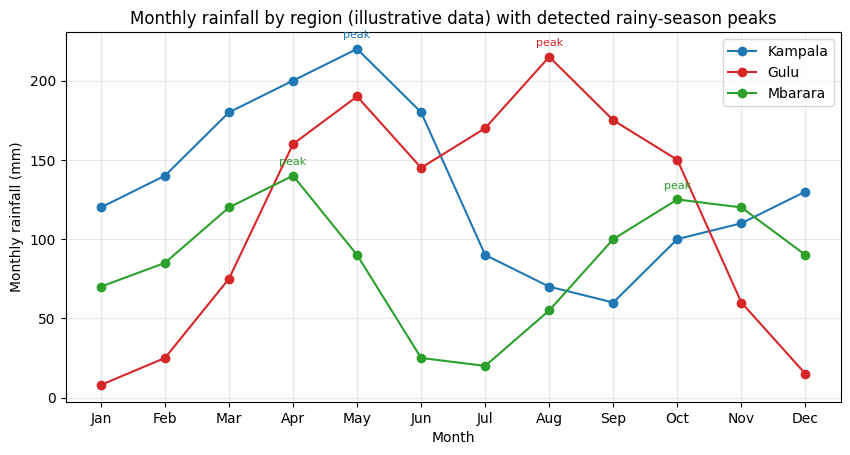

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.8))
colors = {"Kampala": "tab:blue", "Gulu": "tab:red", "Mbarara": "tab:green"}
for r in regions:
    ax.plot(MONTHS, r.rainfall, "o-", color=colors[r.name], label=r.name)
    for m in detect_peaks(r):
        i = MONTHS.index(m); ax.annotate("peak", (i, r.rainfall[i]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8, color=colors[r.name])
ax.set_xlabel("Month"); ax.set_ylabel("Monthly rainfall (mm)"); ax.set_title("Monthly rainfall by region (illustrative data) with detected rainy-season peaks")
ax.legend(); plt.show()

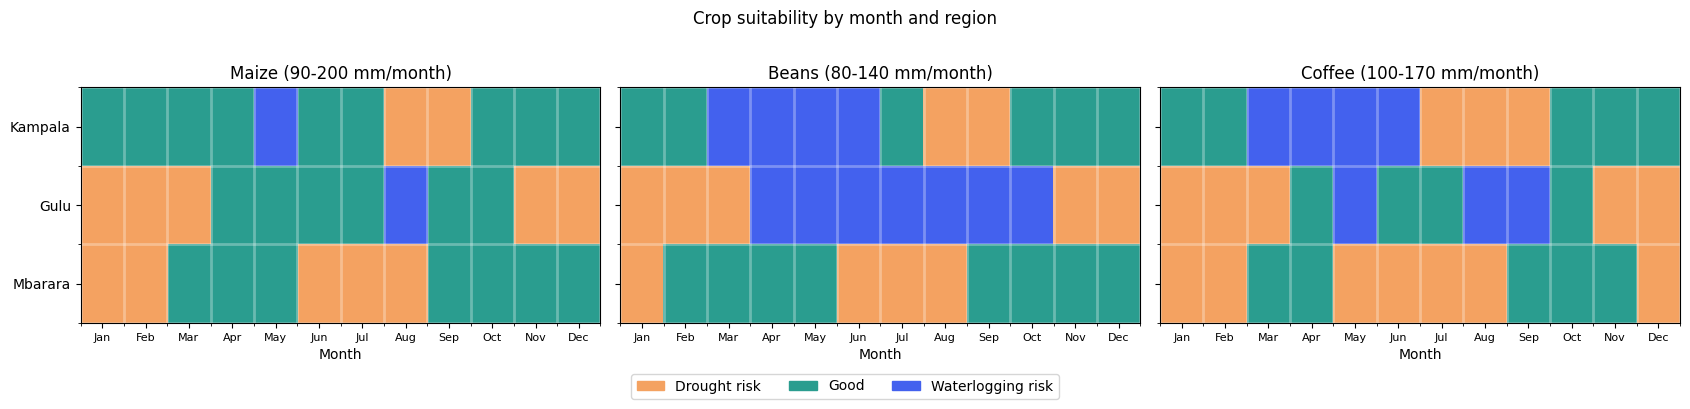

In [8]:
cmap = ListedColormap(["#f4a261", "#2a9d8f", "#4361ee"])          # 0 drought, 1 good, 2 waterlogging
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6), sharey=True)
for ax, (crop, rule) in zip(axes, rules.items()):
    grid = np.array([suitability_codes(r, rule) for r in regions])
    ax.imshow(grid, cmap=cmap, vmin=0, vmax=2, aspect="auto")
    ax.set_xticks(range(12)); ax.set_xticklabels(MONTHS, fontsize=8); ax.set_yticks(range(3)); ax.set_yticklabels([r.name for r in regions])
    ax.set_xticks(np.arange(-.5, 12, 1), minor=True); ax.set_yticks(np.arange(-.5, 3, 1), minor=True)
    ax.grid(which="minor", color="white", lw=2); ax.grid(which="major", visible=False)
    ax.set_title(f"{crop.capitalize()} ({rule.min_mm:g}-{rule.max_mm:g} mm/month)"); ax.set_xlabel("Month")
fig.legend(handles=[Patch(color="#f4a261", label="Drought risk"), Patch(color="#2a9d8f", label="Good"), Patch(color="#4361ee", label="Waterlogging risk")],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Crop suitability by month and region", y=1.02); plt.tight_layout(); plt.show()

The heatmap shows what the line chart cannot: Gulu is almost entirely drought-risk or waterlogging-risk for beans and coffee (few "good" months), Kampala offers a
wide good window for beans and coffee from October to February, and Mbarara has two clean windows (March-May and September-December) for maize and beans.

## Task 7 - Advisory note for Mbarara farmers (<= 200 words)

In [9]:
beans, maize = rules["beans"], rules["maize"]
print("Mbarara bean 3-month windows:", planting_windows(by_name["Mbarara"], beans, 3))
print("Mbarara maize 3-month windows:", planting_windows(by_name["Mbarara"], maize, 3))
print("Mbarara maize 4-month windows:", planting_windows(by_name["Mbarara"], maize, 4))

Mbarara bean 3-month windows: [['Feb', 'Mar', 'Apr'], ['Mar', 'Apr', 'May'], ['Sep', 'Oct', 'Nov'], ['Oct', 'Nov', 'Dec']]
Mbarara maize 3-month windows: [['Mar', 'Apr', 'May'], ['Sep', 'Oct', 'Nov'], ['Oct', 'Nov', 'Dec']]
Mbarara maize 4-month windows: [['Sep', 'Oct', 'Nov', 'Dec']]


**Advisory for Mbarara farmers** (based on illustrative rainfall).

Mbarara has two rainy seasons, about April and October, separated by a dry spell from June to August (only 20-25 mm in June and July). **Grow beans.** Their 3-month cycle
fits both seasons, and the rainfall in the target months stays within the range beans tolerate (80-140 mm).

- **First season: plant in early March.** March, April and May all fall in the good range (120, 140 and 90 mm). Aim to finish harvesting as the rains fade in May-June, because pods dry better in dry weather.
- **Second season: plant in early October.** October to December (125, 120 and 90 mm) is also good. September is a little drier (100 mm), so wait for reliable rain.
- **Avoid** planting in June-August: the rain falls short of what beans need (drought risk).

Maize needs about four months, so plant it in early September (September-December are all good); the March-May window is a month short.
Coffee is marginal: the annual total (1,040 mm) is below the usual 1,200 mm minimum, so avoid new plantings without irrigation.

*Wait for reliable rain; do not plant on the first shower.*

## Extension - real data (not done)

The extension asks for at least 10 years of real monthly rainfall (NASA POWER or UNMA) with box plots per month. This sandbox had no access to those services, so the
notebook uses the illustrative table only. The `Region` class needs no change: build one `Region` per year of data and draw the box plot with
`plt.boxplot([[yr.rainfall[m] for yr in years] for m in range(12)])`. This matters in practice, because one "average year" hides the year-to-year
variability that decides whether a planting date is safe.

## Findings & Limitations

## Findings & Limitations

**Findings.** Kampala is the wettest region (1,600 mm a year) but Gulu is the most seasonal (CV 0.64, near-dry December-February), so timing matters most there.
Last year's `math.cos` method was invalid; the correct dot-product formula matches SciPy to six decimals. The three measures disagree on purpose. Cosine similarity is
0.75-0.89 for every pair because rainfall is non-negative and cosine ignores magnitude (a region five times wetter scores exactly 1.0), while Pearson is close to zero for
Kampala-Gulu (-0.07), showing that their wet and dry months do not line up. Euclidean distance ranks Kampala-Mbarara as closest (250 mm) and is the right choice when the *amount*
of water matters. Peak detection labels Mbarara bimodal at every threshold, which agrees with southern Uganda. Gulu is unimodal at a 25 % prominence threshold but bimodal at 20 % or lower,
which fits a northern or transition-zone regime. For Mbarara the clear recommendation is beans, planted in early March and again in early October.

**Limitations.** The data are illustrative and one "average year" only. Kampala is classified unimodal, which contradicts the known
March-May and September-November regime; the sample's weak short rains and wet January-February are the likely cause, not the method. The crop
thresholds are rough monthly equivalents of seasonal water needs and ignore soil, temperature, variety, evapotranspiration and rainfall reliability. The
prominence threshold is a judgement call, and the sensitivity table shows it can change the label. Real multi-year data (NASA POWER, UNMA) would allow box plots of variability.